# Research questions

Inputs: `results/metrics/<variant>/rq*/` (run_metrics_pipeline.sh). Plots: `results/plots/rq*_*`. Titles only in PNG.

In [ ]:
# Setup: code/libs importable, library changes re-imported automatically
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'code' / 'libs').exists())
sys.path.insert(0, str(PROJECT / 'code' / 'libs'))

from utils import constants as cons
from viz import rq_plots
from viz.figures import save_figure
from viz.style import apply_style

apply_style()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


'DejaVu Serif'

In [ ]:
# Parameters
SMOKE = False                                  # True: smoke-test outputs in tmp/smoke/, False: results/
VARIANT = 'main'                               # metrics/<VARIANT> (robustness checks: 'robustness/<check>')
SAVE = True
FORMATS = ['pdf']                              # e.g. ['png', 'pdf']
RQ1_MEASURE = 'omega2'                         # 'shapley_r2' (shares, + residual) | 'omega2' (partial omega^2)
RQ1_METRICS = None                             # None (all) | a family / subgroup ('technical', 'factuality') | [metric keys]
RQ2_VALUE = 'emm'                              # bars: 'deviation' (from the grand mean) | 'emm' (estimated marginal mean)
RQ2_FOREST = 'contrast'                        # forest: 'contrast' (vs the reference value) | 'deviation'
RQ2_METRICS = None                             # heatmap columns: None (all) | a family / subgroup | [metric keys]
RQ3_TECHNICAL = cons.RQ3_TECHNICAL_METRICS        # x axis: summed; refusals, duplicates as 1 - x
RQ3_SOCIAL = cons.RQ3_SOCIAL_METRICS              # y axis: summed (default: the 6 parities)
RQ3_PARETO = False                             # dotted line through the Pareto front
RQ3_GRID = False                               # background grid (False: only the split lines)
RESULTS_DIR = PROJECT / 'tmp' / 'smoke' if SMOKE else Path(cons.DEFAULT_RESULTS_DIR)
METRICS_DIR = RESULTS_DIR / 'metrics' / VARIANT
PLOTS_DIR = RESULTS_DIR / 'plots'
CONFIG = PROJECT / 'config' / ('analysis_smoke.yaml' if SMOKE else 'analysis.yaml')
from utils import analysis_config
analysis_config.require_late_reviewed(CONFIG)  # RQs need the late settings (thresholds, valid tags) reviewed

## RQ1. Global influence of each variable

In [ ]:
# Data: partial omega^2 and Shapley R^2 of the model and of every configuration variable, per metric
rq1 = rq_plots.load_rq1(METRICS_DIR / 'rq1')
print(f"{rq1['metric'].nunique()} metrics | {rq1['n_models'].max()} models | {rq1['n_configs'].max():,} configurations")

26 metrics | 43 models | 92,880 configurations


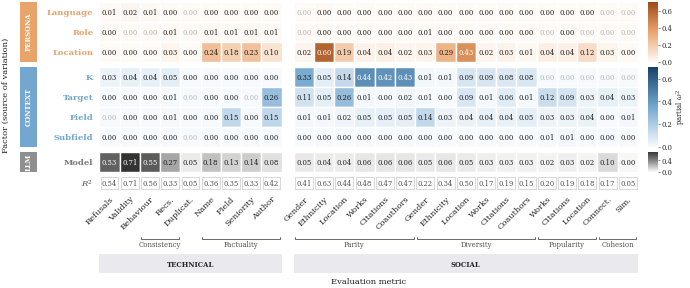

In [ ]:
# Heatmap: RQ1_METRICS (TECHNICAL | SOCIAL); faded = 95% CI includes 0; bottom row: residual (1 - R^2) for
# Shapley R^2, the model's R^2 for omega^2 (fit_row= 'residual' | 'r2' | None to choose)
fig = rq_plots.plot_rq1_heatmap(rq1, RQ1_MEASURE, RQ1_METRICS)
if SAVE:
    save_figure(fig, rq_plots.rq1_figure_name('heatmap', RQ1_MEASURE, RQ1_METRICS), PLOTS_DIR, FORMATS)

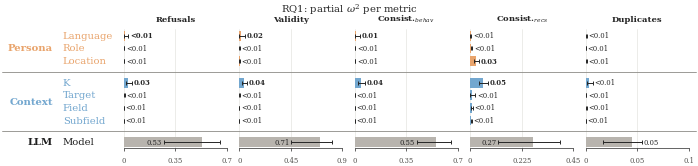

In [ ]:
# Bars: rows = prompt composition (persona, context) + LLM, columns = RQ1_METRICS; 95% CI; bold = largest of its group
metric_group = 'technical'
fig = rq_plots.plot_rq1(rq1, RQ1_MEASURE, metric_group)
if SAVE:
    save_figure(fig, rq_plots.rq1_figure_name('bars', RQ1_MEASURE, metric_group), PLOTS_DIR, FORMATS)

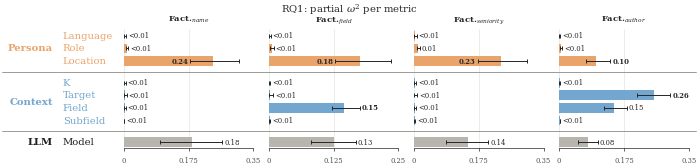

In [ ]:
# Bars: rows = prompt composition (persona, context) + LLM, columns = RQ1_METRICS; 95% CI; bold = largest of its group
metric_group = 'factuality'
fig = rq_plots.plot_rq1(rq1, RQ1_MEASURE, metric_group)
if SAVE:
    save_figure(fig, rq_plots.rq1_figure_name('bars', RQ1_MEASURE, metric_group), PLOTS_DIR, FORMATS)

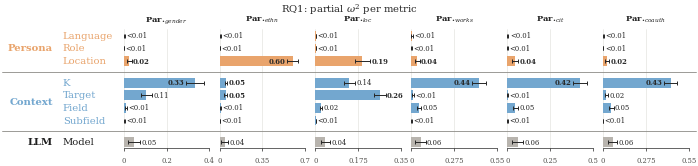

In [ ]:
# Bars: rows = prompt composition (persona, context) + LLM, columns = RQ1_METRICS; 95% CI; bold = largest of its group
metric_group = 'parity'
fig = rq_plots.plot_rq1(rq1, RQ1_MEASURE, metric_group)
if SAVE:
    save_figure(fig, rq_plots.rq1_figure_name('bars', RQ1_MEASURE, metric_group), PLOTS_DIR, FORMATS)

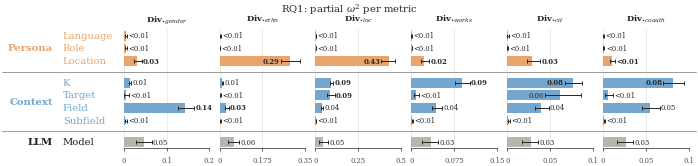

In [ ]:
# Bars: rows = prompt composition (persona, context) + LLM, columns = RQ1_METRICS; 95% CI; bold = largest of its group
metric_group = 'diversity'
fig = rq_plots.plot_rq1(rq1, RQ1_MEASURE, metric_group)
if SAVE:
    save_figure(fig, rq_plots.rq1_figure_name('bars', RQ1_MEASURE, metric_group), PLOTS_DIR, FORMATS)

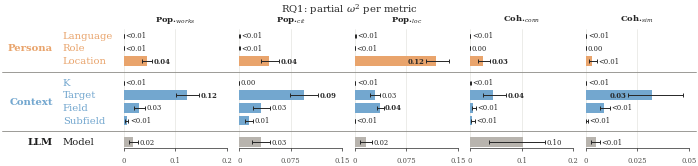

In [ ]:
# Bars: rows = prompt composition (persona, context) + LLM, columns = RQ1_METRICS; 95% CI; bold = largest of its group
metric_group = 'popularity_cohesion'
fig = rq_plots.plot_rq1(rq1, RQ1_MEASURE, metric_group)
if SAVE:
    save_figure(fig, rq_plots.rq1_figure_name('bars', RQ1_MEASURE, metric_group), PLOTS_DIR, FORMATS)

In [ ]:
# Table: RQ1_MEASURE [CI] per variable and metric
rq1.assign(value=rq1.apply(lambda r: f"{r[RQ1_MEASURE]:.3f} [{r[RQ1_MEASURE + '_ci_low']:.3f}, {r[RQ1_MEASURE + '_ci_high']:.3f}]", axis=1)) \
   .pivot(index='variable', columns='metric', values='value')

metric,behaviour_consistency,connectedness,diversity_collaboration,diversity_ethnicity,diversity_gender,diversity_influence,diversity_location,diversity_productivity,duplicates,factuality_author,...,parity_influence,parity_location,parity_productivity,popularity_influence,popularity_location,popularity_productivity,recommendation_consistency,refusals,similarity,validity
variable,,,,,,,,,,,,,,,,,,,,,
field,"0.001 [0.000, 0.002]","0.005 [0.003, 0.011]","0.055 [0.045, 0.066]","0.028 [0.021, 0.037]","0.144 [0.126, 0.164]","0.039 [0.032, 0.048]","0.036 [0.030, 0.046]","0.044 [0.036, 0.054]","0.000 [0.000, 0.001]","0.149 [0.121, 0.183]",...,"0.048 [0.036, 0.062]","0.022 [0.018, 0.027]","0.046 [0.034, 0.061]","0.032 [0.021, 0.045]","0.037 [0.032, 0.042]","0.030 [0.020, 0.041]","0.008 [0.005, 0.013]","0.000 [-0.000, 0.001]","0.009 [0.007, 0.012]","0.001 [0.000, 0.002]"
k,"0.042 [0.021, 0.069]","0.000 [-0.000, 0.001]","0.082 [0.071, 0.095]","0.011 [0.009, 0.013]","0.014 [0.012, 0.018]","0.077 [0.067, 0.088]","0.092 [0.083, 0.102]","0.089 [0.077, 0.102]","0.003 [0.002, 0.007]","0.001 [0.001, 0.002]",...,"0.423 [0.382, 0.464]","0.138 [0.118, 0.161]","0.435 [0.390, 0.479]","-0.000 [-0.000, 0.000]","0.000 [-0.000, 0.001]","0.000 [-0.000, 0.000]","0.055 [0.037, 0.078]","0.031 [0.012, 0.054]","0.000 [-0.000, 0.000]","0.045 [0.026, 0.070]"
language,"0.010 [0.001, 0.037]","0.000 [-0.000, 0.000]","0.000 [0.000, 0.001]","0.003 [0.001, 0.007]","0.004 [0.002, 0.007]","0.001 [0.000, 0.002]","0.002 [0.001, 0.004]","0.000 [0.000, 0.001]","0.000 [-0.000, 0.001]","0.001 [0.000, 0.003]",...,"0.001 [0.000, 0.007]","0.000 [0.000, 0.002]","0.001 [0.000, 0.008]","0.000 [0.000, 0.001]","0.001 [0.000, 0.002]","0.000 [0.000, 0.000]","0.002 [0.000, 0.006]","0.007 [0.001, 0.032]","0.000 [-0.000, 0.000]","0.017 [0.001, 0.050]"
location,"0.001 [0.000, 0.004]","0.025 [0.016, 0.038]","0.010 [0.008, 0.014]","0.286 [0.250, 0.328]","0.031 [0.024, 0.042]","0.029 [0.023, 0.039]","0.426 [0.384, 0.466]","0.022 [0.017, 0.031]","0.000 [0.000, 0.001]","0.098 [0.072, 0.139]",...,"0.044 [0.029, 0.065]","0.191 [0.160, 0.223]","0.035 [0.023, 0.054]","0.044 [0.032, 0.057]","0.119 [0.104, 0.138]","0.045 [0.036, 0.055]","0.026 [0.018, 0.041]","0.002 [0.000, 0.004]","0.003 [0.002, 0.005]","0.003 [0.001, 0.008]"
model,"0.553 [0.421, 0.656]","0.102 [0.038, 0.144]","0.026 [0.017, 0.036]","0.058 [0.033, 0.080]","0.048 [0.029, 0.065]","0.027 [0.017, 0.036]","0.046 [0.019, 0.074]","0.034 [0.019, 0.047]","0.045 [0.016, 0.055]","0.078 [0.050, 0.104]",...,"0.062 [0.028, 0.095]","0.040 [0.022, 0.060]","0.060 [0.025, 0.092]","0.032 [0.018, 0.045]","0.016 [0.008, 0.025]","0.018 [0.009, 0.027]","0.273 [0.123, 0.392]","0.528 [0.271, 0.654]","0.005 [0.003, 0.007]","0.705 [0.454, 0.812]"
role,"0.001 [-0.000, 0.004]","-0.000 [-0.000, 0.000]","0.001 [0.000, 0.002]","0.001 [0.000, 0.002]","0.005 [0.003, 0.008]","0.001 [0.000, 0.001]","0.001 [0.000, 0.002]","0.001 [0.000, 0.002]","0.000 [-0.000, 0.000]","0.005 [0.003, 0.008]",...,"0.001 [0.000, 0.002]","0.001 [0.000, 0.003]","0.001 [0.000, 0.002]","0.000 [0.000, 0.001]","0.000 [-0.000, 0.000]","0.000 [-0.000, 0.000]","0.006 [0.003, 0.010]","0.001 [0.000, 0.005]","-0.000 [-0.000, 0.000]","0.000 [-0.000, 0.006]"
seniority,"0.001 [0.000, 0.003]","0.045 [0.024, 0.069]","0.006 [0.003, 0.011]","0.001 [0.000, 0.004]","0.005 [0.001, 0.013]","0.062 [0.044, 0.086]","0.087 [0.067, 0.111]","0.008 [0.005, 0.013]","0.000 [-0.000, 0.001]","0.255 [0.210, 0.300]",...,"0.003 [0.001, 0.007]","0.263 [0.237, 0.287]","0.008 [0.004, 0.016]","0.094 [0.074, 0.115]","0.029 [0.023, 0.037]","0.123 [0.100, 0.146]","0.008 [0.001, 0.023]","0.004 [0.001, 0.007]","0.032 [0.021, 0.047]","0.001 [0.000, 0.004]"
subfield,"0.000 [0.000, 0.001]","0.004 [0.002, 0.010]","0.001 [0.001, 0.002]","0.003 [0.002, 0.005]","0.004 [0.002, 0.006]","0.001 [0.001, 0.003]","0.002 [0.001, 0.004]","0.001 [0.001, 0.002]","0.000 [-0.000, 0.000]","0.002 [0.001, 0.004]",...,"0.001 [0.000, 0.002]","0.001 [0.000, 

## RQ2. Local influence of each value

In [ ]:
# Data: EMM and deviation from the grand mean of every value of every configuration variable, per metric
rq2 = rq_plots.load_rq2(METRICS_DIR / 'rq2')
print(f"{rq2['metric'].nunique()} metrics | {rq2['n_models'].max()} models | {rq2['n_configs'].max():,} configurations")


26 metrics | 43 models | 92,880 configurations


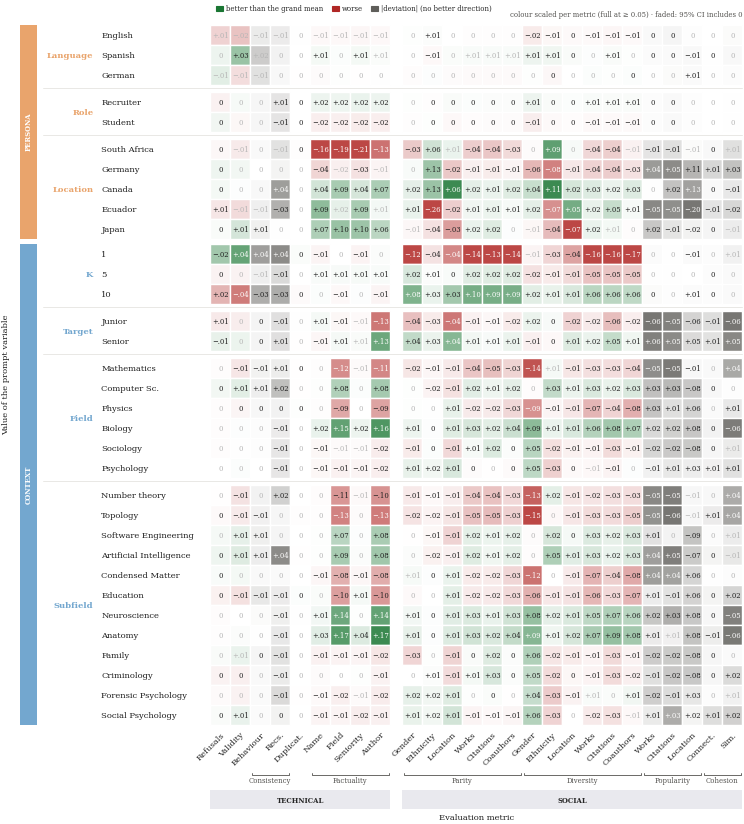

In [ ]:
# Heatmap: deviations, green = better than the grand mean, red = worse, grey = no better direction; faded = CI includes 0
fig = rq_plots.plot_rq2_heatmap(rq2, RQ2_METRICS)
if SAVE:
    save_figure(fig, rq_plots.rq2_figure_name('heatmap', 'deviation', RQ2_METRICS), PLOTS_DIR, FORMATS)


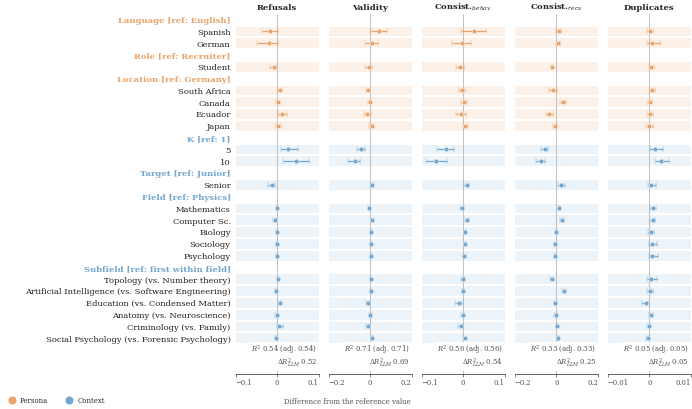

In [ ]:
# Forest: one dot + 95% CI per value, technical metrics; R^2, adjusted R^2, Delta R^2 (LLM) per panel
metric_group = 'technical'
fig = rq_plots.plot_rq2_forest(rq2, RQ2_FOREST, metric_group)
if SAVE:
    save_figure(fig, rq_plots.rq2_figure_name('forest', RQ2_FOREST, metric_group), PLOTS_DIR, FORMATS)


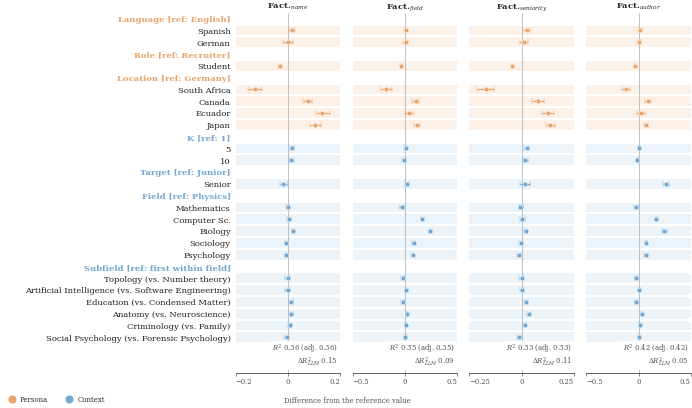

In [ ]:
# Forest: one dot + 95% CI per value, factuality metrics; R^2, adjusted R^2, Delta R^2 (LLM) per panel
metric_group = 'factuality'
fig = rq_plots.plot_rq2_forest(rq2, RQ2_FOREST, metric_group)
if SAVE:
    save_figure(fig, rq_plots.rq2_figure_name('forest', RQ2_FOREST, metric_group), PLOTS_DIR, FORMATS)


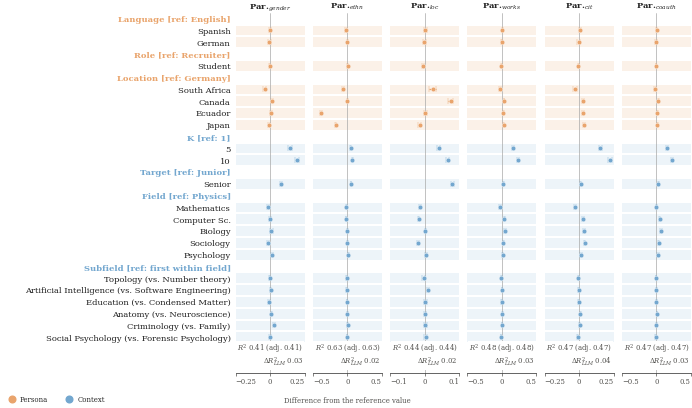

In [ ]:
# Forest: one dot + 95% CI per value, social metrics; R^2, adjusted R^2, Delta R^2 (LLM) per panel
metric_group = 'parity'
fig = rq_plots.plot_rq2_forest(rq2, RQ2_FOREST, metric_group)
if SAVE:
    save_figure(fig, rq_plots.rq2_figure_name('forest', RQ2_FOREST, metric_group), PLOTS_DIR, FORMATS)


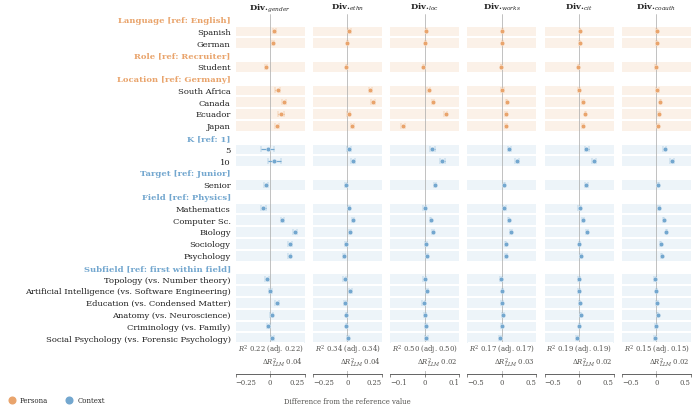

In [ ]:
# Forest: one dot + 95% CI per value, social metrics; R^2, adjusted R^2, Delta R^2 (LLM) per panel
metric_group = 'diversity'
fig = rq_plots.plot_rq2_forest(rq2, RQ2_FOREST, metric_group)
if SAVE:
    save_figure(fig, rq_plots.rq2_figure_name('forest', RQ2_FOREST, metric_group), PLOTS_DIR, FORMATS)


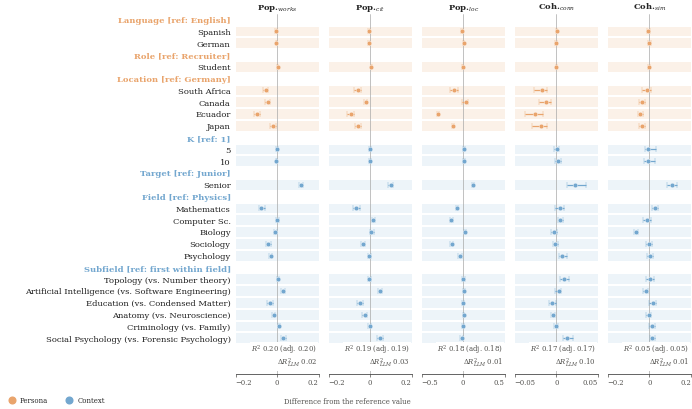

In [ ]:
# Forest: one dot + 95% CI per value, social metrics; R^2, adjusted R^2, Delta R^2 (LLM) per panel
metric_group = 'popularity_cohesion'
fig = rq_plots.plot_rq2_forest(rq2, RQ2_FOREST, metric_group)
if SAVE:
    save_figure(fig, rq_plots.rq2_figure_name('forest', RQ2_FOREST, metric_group), PLOTS_DIR, FORMATS)


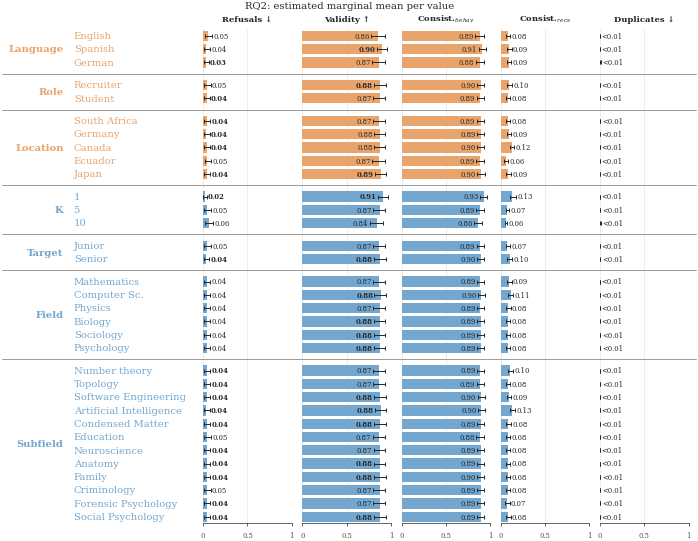

In [ ]:
# Bars: rows = values of the configuration variables, columns = technical metrics; 95% CI
group_metric = 'technical'
fig = rq_plots.plot_rq2(rq2, RQ2_VALUE, group_metric)
if SAVE:
    save_figure(fig, rq_plots.rq2_figure_name('bars', RQ2_VALUE, group_metric), PLOTS_DIR, FORMATS)


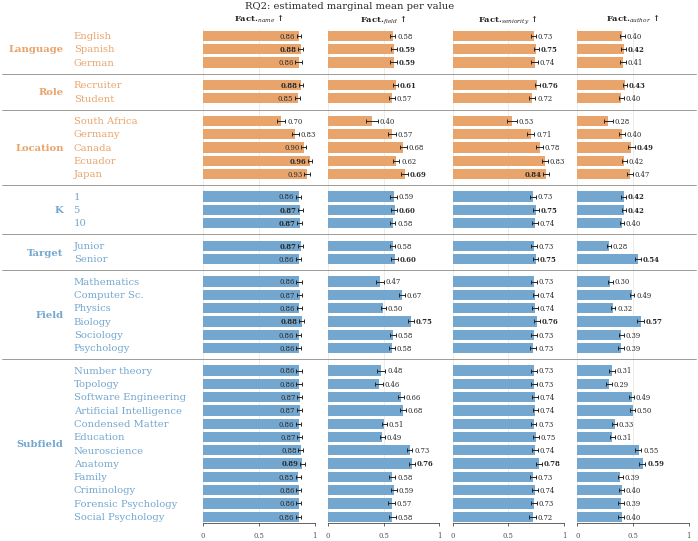

In [ ]:
# Bars: rows = values of the configuration variables, columns = technical metrics; 95% CI
group_metric = 'factuality'
fig = rq_plots.plot_rq2(rq2, RQ2_VALUE, group_metric)
if SAVE:
    save_figure(fig, rq_plots.rq2_figure_name('bars', RQ2_VALUE, group_metric), PLOTS_DIR, FORMATS)


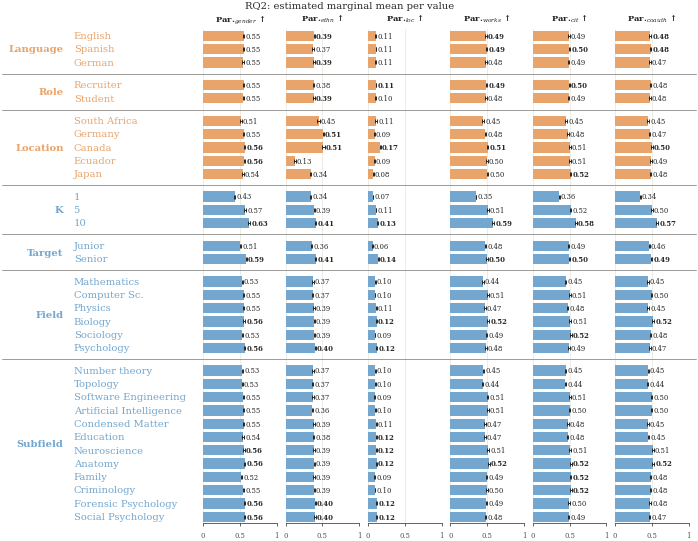

In [ ]:
# Bars: rows = values of the configuration variables, columns = technical metrics; 95% CI
group_metric = 'parity'
fig = rq_plots.plot_rq2(rq2, RQ2_VALUE, group_metric)
if SAVE:
    save_figure(fig, rq_plots.rq2_figure_name('bars', RQ2_VALUE, group_metric), PLOTS_DIR, FORMATS)


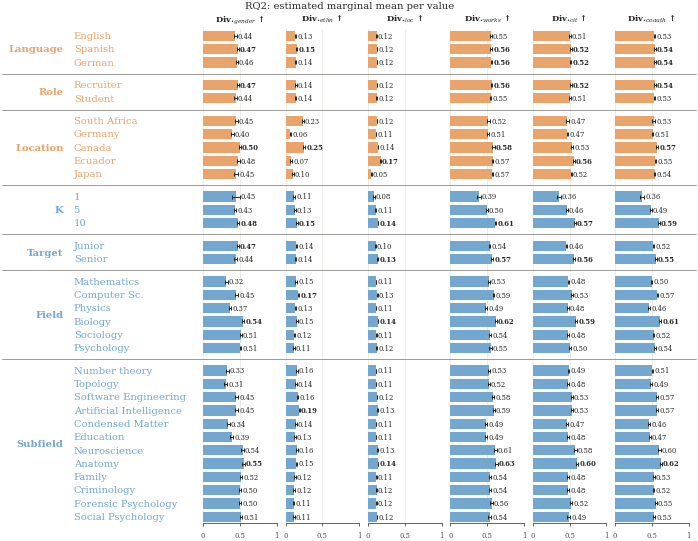

In [ ]:
# Bars: rows = values of the configuration variables, columns = technical metrics; 95% CI
group_metric = 'diversity'
fig = rq_plots.plot_rq2(rq2, RQ2_VALUE, group_metric)
if SAVE:
    save_figure(fig, rq_plots.rq2_figure_name('bars', RQ2_VALUE, group_metric), PLOTS_DIR, FORMATS)


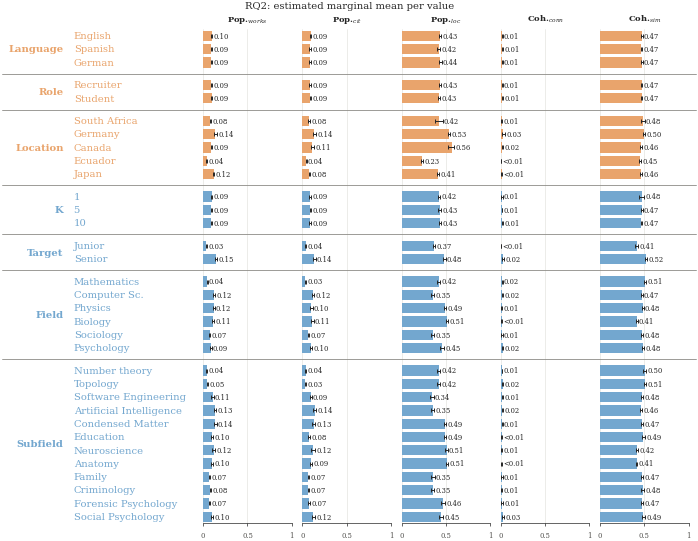

In [ ]:
# Bars: rows = values of the configuration variables, columns = technical metrics; 95% CI
group_metric = 'popularity_cohesion'
fig = rq_plots.plot_rq2(rq2, RQ2_VALUE, group_metric)
if SAVE:
    save_figure(fig, rq_plots.rq2_figure_name('bars', RQ2_VALUE, group_metric), PLOTS_DIR, FORMATS)


## RQ3. Socio-technical trade-off

In [ ]:
# Data: per model, the mean of each metric over its configurations; technical / social score = their sums
from analysis import tradeoff
from metrics import summary
rq3 = tradeoff.model_scores(summary.configuration_table(METRICS_DIR), RQ3_TECHNICAL, RQ3_SOCIAL)
rq3.assign(quadrant_relative=tradeoff.quadrants(rq3, 'relative'), quadrant_absolute=tradeoff.quadrants(rq3, 'absolute'),
           pareto=tradeoff.pareto_front(rq3)).sort_values('technical', ascending=False).round(3)


,model,validity,refusals,duplicates,factuality_name,factuality_name_field,factuality_name_seniority,factuality_author,parity_gender,parity_ethnicity,...,parity_influence,parity_collaboration,technical,social,technical_max,social_max,n_missing,quadrant_relative,quadrant_absolute,pareto
3,dolphin-mixtral-8x22b-v2_9-q4_K_M,1.000,1.000,1.000,0.979,0.767,0.912,0.566,0.544,0.308,...,0.489,0.476,6.225,2.403,7,6,0,Q4,Q4,True
4,dolphin-mixtral-8x7b-v2_7-q4_K_M,0.996,1.000,0.995,0.917,0.715,0.846,0.506,0.568,0.358,...,0.507,0.506,5.976,2.568,7,6,0,Q1,Q4,True
8,falcon3-7b-instruct-q4_K_M,0.978,1.000,0.999,0.936,0.666,0.843,0.491,0.493,0.405,...,0.477,0.456,5.914,2.416,7,6,0,Q4,Q4,False
27,mistral-small-22b-instruct-2409-q4_K_M,0.999,1.000,1.000,0.927,0.675,0.835,0.460,0.564,0.372,...,0.510,0.498,5.895,2.574,7,6,0,Q1,Q4,True
7,falcon3-10b-instruct-q4_K_M,1.000,1.000,1.000,0.919,0.642,0.837,0.446,0.585,0.391,...,0.540,0.518,5.844,2.693,7,6,0,Q1,Q4,True
25,mistral-large-123b-instruct-2411-q4_K_M,0.874,0.897,1.000,0.957,0.745,0.842,0.528,0.576,0.398,...,0.511,0.510,5.844,2.615,7,6,0,Q1,Q4,False
11,gemini-2_5-pro,0.998,1.000,1.000,0.928,0.739,0.674,0.490,0.549,0.423,...,0.465,0.465,5.829,2.441,7,6,0,Q4,Q4,False
1,deepseek-r1-70b-llama-distill-q4_K_M,0.953,0.996,1.000,0.917,0.668,0.801,0.470,0.569,0.404,...,0.508,0.496,5.805,2.581,7,6,0,Q1,Q4,False
18,gpt-oss-120b,0.976,0.992,1.000,0.948,0.622,0.805,0.447,0.561,0.405,...,0.504,0.483,5.790,2.560,7,6,0,Q1,Q4,False
38,qwen3-8b-q4_K_M,0.954,0.992,0.999,0.938,0.623,0.782,0.433,0.545,0.382,...,0.497,0.476,5.722,2.500,7,6,0,Q4,Q4,False


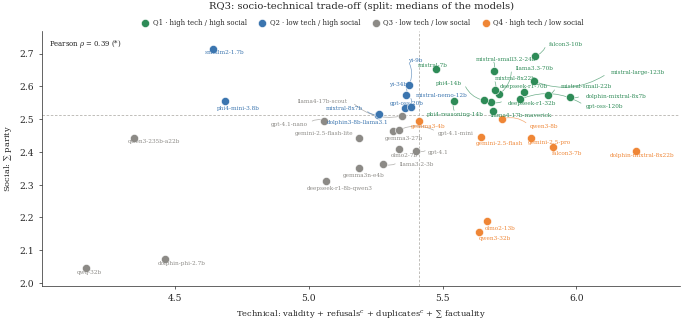

In [ ]:
# Relative: quadrants split at the medians of the models
fig = rq_plots.plot_rq3(rq3, 'relative', RQ3_PARETO, RQ3_TECHNICAL, RQ3_SOCIAL, grid=RQ3_GRID)
if SAVE:
    save_figure(fig, rq_plots.rq3_figure_name('relative', RQ3_TECHNICAL, RQ3_SOCIAL), PLOTS_DIR, FORMATS)


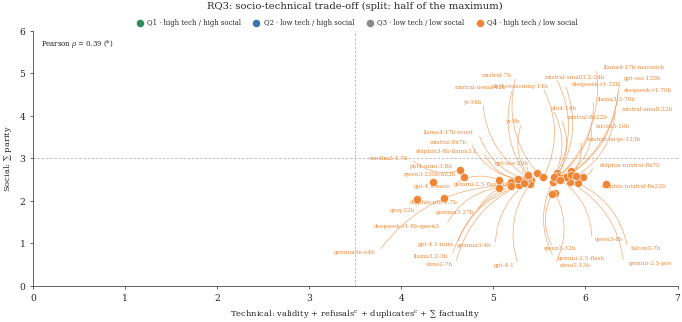

In [ ]:
# Absolute: quadrants split at half of each axis maximum (axes from 0 to the maximum)
fig = rq_plots.plot_rq3(rq3, 'absolute', RQ3_PARETO, RQ3_TECHNICAL, RQ3_SOCIAL, grid=RQ3_GRID)
if SAVE:
    save_figure(fig, rq_plots.rq3_figure_name('absolute', RQ3_TECHNICAL, RQ3_SOCIAL), PLOTS_DIR, FORMATS)
